In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset


np.random.seed(42)
torch.manual_seed(42)


n_samples = 1000
data = {
    'CustomerID': range(1, n_samples + 1),
    'Age': np.random.randint(18, 70, size=n_samples),
    'Tenure': np.random.randint(1, 72, size=n_samples), # Months with company
    'MonthlyCharges': np.random.uniform(20.0, 120.0, size=n_samples),
    'TotalCharges': np.random.uniform(100.0, 8000.0, size=n_samples),
    'Gender': np.random.choice(['Male', 'Female'], size=n_samples),
    'ContractType': np.random.choice(['Month-to-month', 'One year', 'Two year'], size=n_samples, p=[0.5, 0.3, 0.2]),
    'TechSupport': np.random.choice(['Yes', 'No'], size=n_samples, p=[0.3, 0.7]),
    'InternetService': np.random.choice(['DSL', 'Fiber optic', 'No'], size=n_samples, p=[0.4, 0.4, 0.2]),
    'Churn': np.random.choice([0, 1], size=n_samples, p=[0.7, 0.3])
}

df = pd.DataFrame(data)


df.loc[df.sample(frac=0.02).index, 'TotalCharges'] = np.nan

print("Dataset Shape:", df.shape)
display(df.head())


Dataset Shape: (1000, 10)


,CustomerID,Age,Tenure,MonthlyCharges,TotalCharges,Gender,ContractType,TechSupport,InternetService,Churn
0,1,56,15,55.162269,2465.225148,Female,One year,No,No,1
1,2,69,64,30.142083,2933.852651,Female,Two year,No,DSL,1
2,3,46,28,68.587176,6455.053941,Female,One year,No,DSL,0
3,4,32,39,45.677657,2302.202992,Female,Two year,No,DSL,0
4,5,60,57,48.487290,1764.569215,Female,Month-to-month,Yes,No,0


In [3]:

df['TotalCharges'] = df['TotalCharges'].fillna(df['TotalCharges'].median())


label_encoders = {}
categorical_cols = ['Gender', 'ContractType', 'TechSupport', 'InternetService']

for col in categorical_cols:
    le = LabelEncoder()
    df[col] = le.fit_transform(df[col])
    label_encoders[col] = le


X = df.drop(columns=['CustomerID', 'Churn'])
y = df['Churn']


X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)


scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Preprocessed training shape:", X_train_scaled.shape)
print("Preprocessed testing shape:", X_test_scaled.shape)


Preprocessed training shape: (800, 8)
Preprocessed testing shape: (200, 8)


/tmp/ipykernel_4255/3484271295.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(ax=axes[0], x='Churn', data=df, palette='Set2')
/tmp/ipykernel_4255/3484271295.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(ax=axes[1], x='Churn', y='Age', data=df, palette='Set2')
/tmp/ipykernel_4255/3484271295.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(ax=axes[2], x='Churn', y='MonthlyCharges', data=df, palette='Set2')


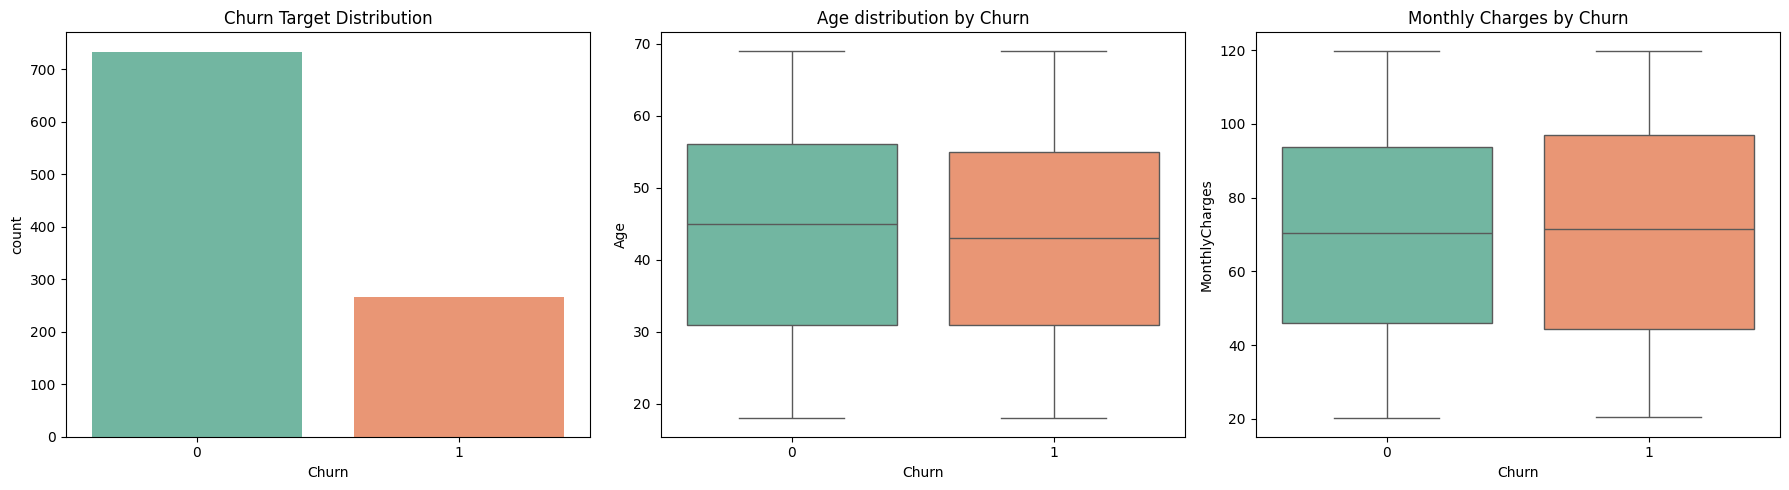

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))


sns.countplot(ax=axes[0], x='Churn', data=df, palette='Set2')
axes[0].set_title('Churn Target Distribution')


sns.boxplot(ax=axes[1], x='Churn', y='Age', data=df, palette='Set2')
axes[1].set_title('Age distribution by Churn')


sns.boxplot(ax=axes[2], x='Churn', y='MonthlyCharges', data=df, palette='Set2')
axes[2].set_title('Monthly Charges by Churn')

plt.tight_layout()
plt.show()


In [5]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC


ml_models = {
    'KNN': KNeighborsClassifier(n_neighbors=5),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42),
    'SVM': SVC(probability=True, random_state=42)
}


ml_results = {}
for name, model in ml_models.items():
    model.fit(X_train_scaled, y_train)
    preds = model.predict(X_test_scaled)

    ml_results[name] = {
        'Accuracy': accuracy_score(y_test, preds),
        'Precision': precision_score(y_test, preds, zero_division=0),
        'Recall': recall_score(y_test, preds),
        'F1-Score': f1_score(y_test, preds),
        'Predictions': preds
    }


ml_df = pd.DataFrame(ml_results).T
display(ml_df.iloc[:, :4])


,Accuracy,Precision,Recall,F1-Score
KNN,0.655,0.233333,0.132075,0.168675
Random Forest,0.72,0.2,0.018868,0.034483
SVM,0.73,0.0,0.0,0.0


In [6]:

X_train_tensor = torch.FloatTensor(X_train_scaled)
y_train_tensor = torch.FloatTensor(y_train.values).unsqueeze(1)
X_test_tensor = torch.FloatTensor(X_test_scaled)
y_test_tensor = torch.FloatTensor(y_test.values).unsqueeze(1)


class ChurnANN(nn.Module):
    def __init__(self, input_dim):
        super(ChurnANN, self).__init__()
        self.fc1 = nn.Linear(input_dim, 16)
        self.relu = nn.ReLU()
        self.fc2 = nn.Linear(16, 8)
        self.fc3 = nn.Linear(8, 1)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        out = self.fc1(x)
        out = self.relu(out)
        out = self.fc2(out)
        out = self.relu(out)
        out = self.fc3(out)
        out = self.sigmoid(out)
        return out

model_ann = ChurnANN(X_train_scaled.shape[1])
criterion = nn.BCELoss()
optimizer = optim.Adam(model_ann.parameters(), lr=0.01)


train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)

epochs = 40
train_losses = []
train_accs = []

for epoch in range(epochs):
    model_ann.train()
    epoch_loss = 0
    correct = 0
    total = 0

    for batch_x, batch_y in train_loader:
        optimizer.zero_grad()
        outputs = model_ann(batch_x)
        loss = criterion(outputs, batch_y)
        loss.backward()
        optimizer.step()

        epoch_loss += loss.item() * batch_x.size(0)
        preds = (outputs >= 0.5).float()
        correct += (preds == batch_y).sum().item()
        total += batch_y.size(0)

    train_losses.append(epoch_loss / total)
    train_accs.append(correct / total)


model_ann.eval()
with torch.no_grad():
    ann_outputs = model_ann(X_test_tensor)
    ann_preds = (ann_outputs >= 0.5).float().numpy()


ml_results['Neural Network'] = {
    'Accuracy': accuracy_score(y_test, ann_preds),
    'Precision': precision_score(y_test, ann_preds, zero_division=0),
    'Recall': recall_score(y_test, ann_preds),
    'F1-Score': f1_score(y_test, ann_preds),
    'Predictions': ann_preds.flatten()
}


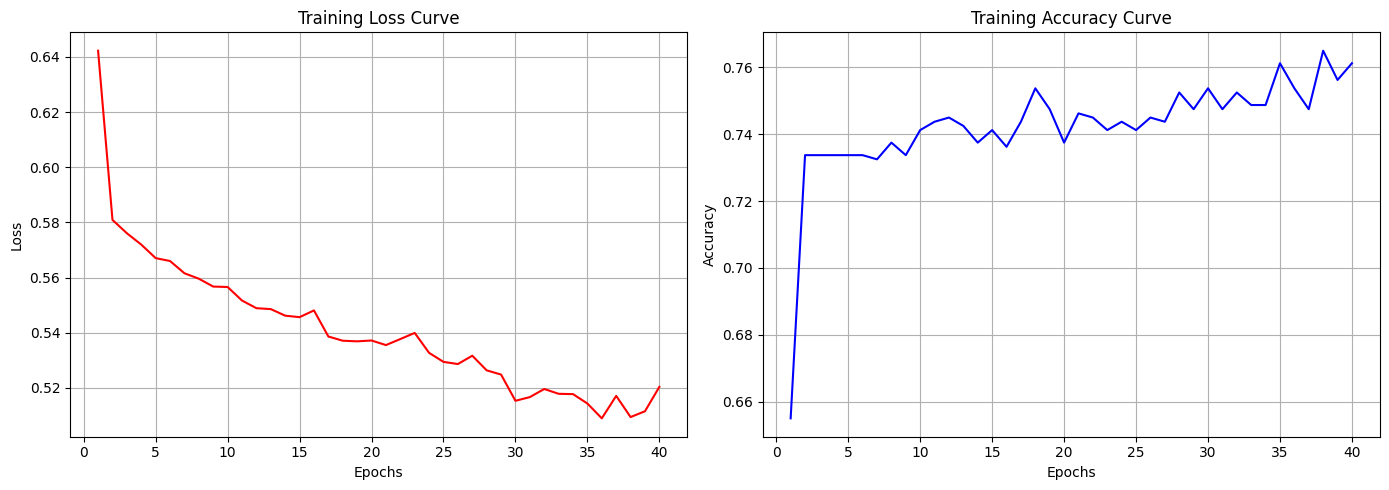

In [7]:

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(range(1, epochs + 1), train_losses, label='Loss', color='red')
axes[0].set_title('Training Loss Curve')
axes[0].set_xlabel('Epochs')
axes[0].set_ylabel('Loss')
axes[0].grid(True)

axes[1].plot(range(1, epochs + 1), train_accs, label='Accuracy', color='blue')
axes[1].set_title('Training Accuracy Curve')
axes[1].set_xlabel('Epochs')
axes[1].set_ylabel('Accuracy')
axes[1].grid(True)

plt.tight_layout()
plt.show()


,Accuracy,Precision,Recall,F1-Score
KNN,0.655,0.233333,0.132075,0.168675
Random Forest,0.72,0.2,0.018868,0.034483
SVM,0.73,0.0,0.0,0.0
Neural Network,0.685,0.0,0.0,0.0


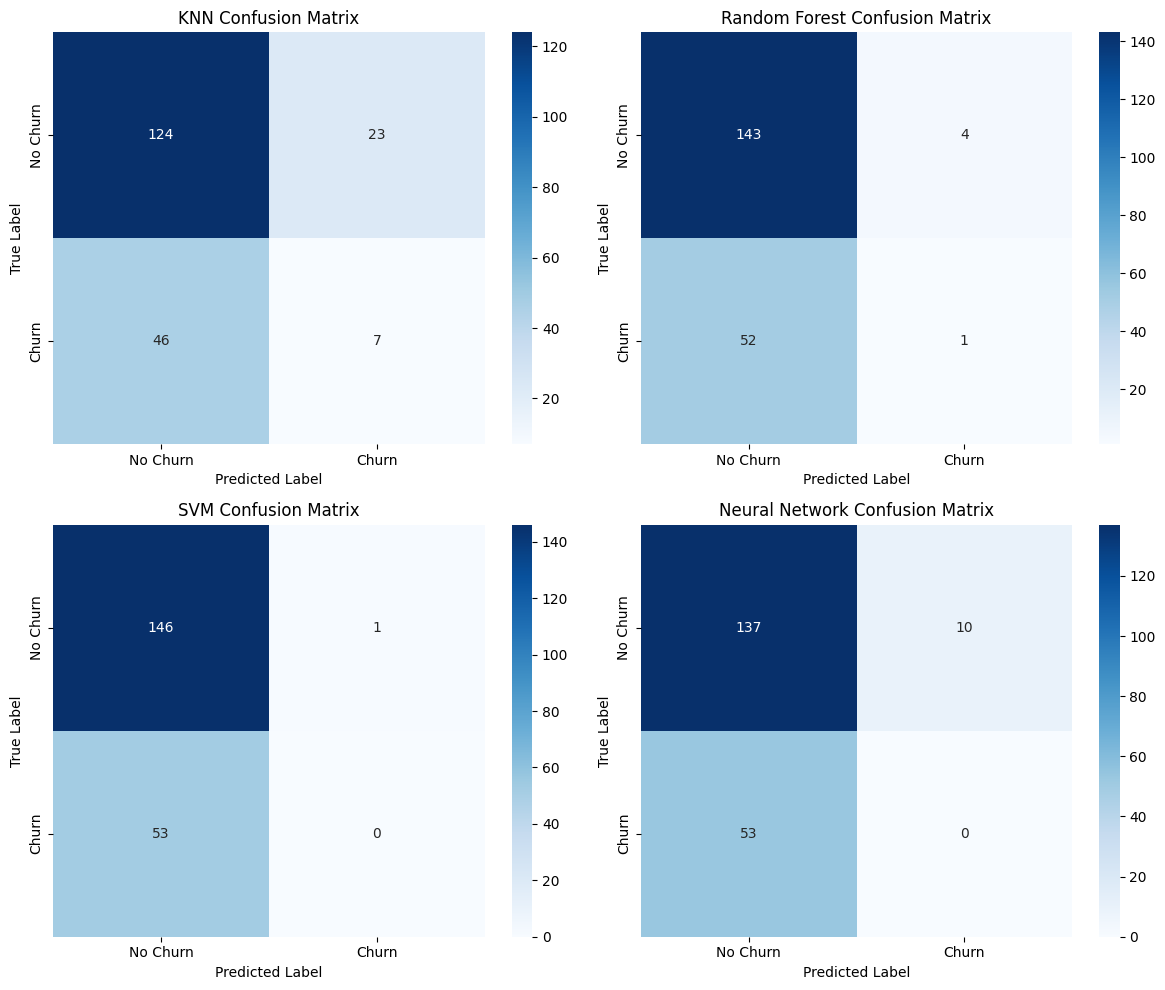

In [8]:
comparison_df = pd.DataFrame(ml_results).T
comparison_df = comparison_df.drop(columns=['Predictions'])
display(comparison_df)


fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.ravel()

for i, (name, res) in enumerate(ml_results.items()):
    cm = confusion_matrix(y_test, res['Predictions'])
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[i],
                xticklabels=['No Churn', 'Churn'], yticklabels=['No Churn', 'Churn'])
    axes[i].set_title(f'{name} Confusion Matrix')
    axes[i].set_ylabel('True Label')
    axes[i].set_xlabel('Predicted Label')

plt.tight_layout()
plt.show()


In [9]:
def predict_new_customer(model_choice, new_customer_data):

    cust_df = pd.DataFrame([new_customer_data])


    for col in categorical_cols:
        cust_df[col] = label_encoders[col].transform(cust_df[col])


    scaled_features = scaler.transform(cust_df)

    if model_choice == 'Neural Network':
        model_ann.eval()
        with torch.no_grad():
            tensor_input = torch.FloatTensor(scaled_features)
            prob = model_ann(tensor_input).item()
    else:
        clf = ml_models[model_choice]
        prob = clf.predict_proba(scaled_features)[0][1]

    prediction = "Churn" if prob >= 0.5 else "No Churn"
    print(f"Selected Model: {model_choice}")
    print(f"Predicted Class: {prediction} (Probability of Churn: {prob:.2%})")


new_client = {
    'Age': 45,
    'Tenure': 12,
    'MonthlyCharges': 89.5,
    'TotalCharges': 1074.0,
    'Gender': 'Female',
    'ContractType': 'Month-to-month',
    'TechSupport': 'No',
    'InternetService': 'Fiber optic'
}

predict_new_customer('Neural Network', new_client)


Selected Model: Neural Network
Predicted Class: No Churn (Probability of Churn: 27.23%)


In [10]:

pip install -q gradio

In [ ]:
import gradio as gr
import pandas as pd
import torch

def gradio_predict(model_choice, age, tenure, monthly_charges, total_charges, gender, contract_type, tech_support, internet_service):

    input_data = {
        'Age': age,
        'Tenure': tenure,
        'MonthlyCharges': monthly_charges,
        'TotalCharges': total_charges,
        'Gender': gender,
        'ContractType': contract_type,
        'TechSupport': tech_support,
        'InternetService': internet_service
    }

    cust_df = pd.DataFrame([input_data])


    for col in categorical_cols:
        cust_df[col] = label_encoders[col].transform(cust_df[col])


    scaled_features = scaler.transform(cust_df)


    if model_choice == 'Neural Network':
        model_ann.eval()
        with torch.no_grad():
            tensor_input = torch.FloatTensor(scaled_features)
            prob = model_ann(tensor_input).item()
    else:
        clf = ml_models[model_choice]
        prob = clf.predict_proba(scaled_features)[0][1]

    prediction = "Churn 🔴" if prob >= 0.5 else "No Churn 🟢"
    return f"Prediction: {prediction}\nChurn Probability: {prob:.2%}"


inputs = [
    gr.Dropdown(choices=['Neural Network', 'KNN', 'Random Forest', 'SVM'], label="Select Model", value="Neural Network"),
    gr.Slider(minimum=18, maximum=100, step=1, label="Age", value=35),
    gr.Slider(minimum=1, maximum=72, step=1, label="Tenure (Months)", value=12),
    gr.Number(label="Monthly Charges ($)", value=75.0),
    gr.Number(label="Total Charges ($)", value=900.0),
    gr.Dropdown(choices=['Male', 'Female'], label="Gender", value="Female"),
    gr.Dropdown(choices=['Month-to-month', 'One year', 'Two year'], label="Contract Type", value="Month-to-month"),
    gr.Dropdown(choices=['Yes', 'No'], label="Tech Support", value="No"),
    gr.Dropdown(choices=['DSL', 'Fiber optic', 'No'], label="Internet Service", value="Fiber optic")
]


output = gr.Textbox(label="Prediction Result")


app = gr.Interface(
    fn=gradio_predict,
    inputs=inputs,
    outputs=output,
    title="Customer Churn Prediction Dashboard",
    description="Input customer details to check their churn likelihood.",
    theme="soft"
)


app.launch(share=True, debug=True)

/usr/local/lib/python3.13/dist-packages/gradio/interface.py:171: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme. Please pass these parameters to launch() instead.
  super().__init__(


Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://35019f346f396d39c0.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
